In [1]:
pip install pandas numpy matplotlib seaborn jupyter

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\traitlets\config\application.py", line 1082, in launch_instance
    app.start()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\ipykernel\kernelapp.py", line 807,

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\traitlets\config\application.py", line 1082, in launch_instance
    app.start()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\ipykernel\kernelapp.py", line 807,

AttributeError: _ARRAY_API not found

In [6]:

BASE_DIR = Path(
    r"D:\Veda Internship\Sakshi\Super_Store_DataCleaning\COVID19_Global_Impact_Dashboard"
)

DATA_PATH = (
    BASE_DIR
    / "Day2_Covid19_Global_Impact_Dashboard"
    / "Dataset"
    / "owid-covid-data.csv"
)

print("Current folder:", BASE_DIR)
print("Dataset path:", DATA_PATH)
print("File exists:", DATA_PATH.exists())

Current folder: D:\Veda Internship\Sakshi\Super_Store_DataCleaning\COVID19_Global_Impact_Dashboard
Dataset path: D:\Veda Internship\Sakshi\Super_Store_DataCleaning\COVID19_Global_Impact_Dashboard\Day2_Covid19_Global_Impact_Dashboard\Dataset\owid-covid-data.csv
File exists: True


In [7]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())
print(df.info())

Dataset shape: (429435, 67)
  iso_code continent     location        date  total_cases  new_cases  \
0      AFG      Asia  Afghanistan  2020-01-05          0.0        0.0   
1      AFG      Asia  Afghanistan  2020-01-06          0.0        0.0   
2      AFG      Asia  Afghanistan  2020-01-07          0.0        0.0   
3      AFG      Asia  Afghanistan  2020-01-08          0.0        0.0   
4      AFG      Asia  Afghanistan  2020-01-09          0.0        0.0   

   new_cases_smoothed  total_deaths  new_deaths  new_deaths_smoothed  ...  \
0                 NaN           0.0         0.0                  NaN  ...   
1                 NaN           0.0         0.0                  NaN  ...   
2                 NaN           0.0         0.0                  NaN  ...   
3                 NaN           0.0         0.0                  NaN  ...   
4                 NaN           0.0         0.0                  NaN  ...   

   male_smokers  handwashing_facilities  hospital_beds_per_thousand  \

In [8]:
required_cols = [
    "location",
    "date",
    "population",
    "total_cases",
    "new_cases",
    "total_deaths",
    "new_deaths",
    "total_vaccinations",
    "people_vaccinated",
    "people_fully_vaccinated",
    "total_cases_per_million",
    "total_deaths_per_million",
    "new_cases_per_million",
    "new_deaths_per_million"
]

available_cols = [
    col for col in required_cols if col in df.columns
]

covid = df[available_cols].copy()

covid["date"] = pd.to_datetime(
    covid["date"], errors="coerce"
)

covid = covid.dropna(subset=["location", "date"])

covid = covid.drop_duplicates(
    subset=["location", "date"]
)

covid = covid.sort_values(["location", "date"])

print("Cleaned shape:", covid.shape)
print("Duplicate country-date rows:",
      covid.duplicated(["location", "date"]).sum())

print(covid.isnull().sum())

Cleaned shape: (421665, 14)
Duplicate country-date rows: 0
location                         0
date                             0
population                       0
total_cases                  16617
new_cases                    18262
total_deaths                 16617
new_deaths                   17813
total_vaccinations          336342
people_vaccinated           340627
people_fully_vaccinated     343695
total_cases_per_million      16617
total_deaths_per_million     16617
new_cases_per_million        18262
new_deaths_per_million       17813
dtype: int64


In [9]:
# Check data types
print(covid.dtypes)

# Check negative daily values
print("Negative new cases:",
      (covid["new_cases"] < 0).sum())

print("Negative new deaths:",
      (covid["new_deaths"] < 0).sum())

# Check date range
print("Start date:", covid["date"].min())
print("End date:", covid["date"].max())

# Check duplicate records again
print("Duplicate records:",
      covid.duplicated(["location", "date"]).sum())

location                            object
date                        datetime64[ns]
population                           int64
total_cases                        float64
new_cases                          float64
total_deaths                       float64
new_deaths                         float64
total_vaccinations                 float64
people_vaccinated                  float64
people_fully_vaccinated            float64
total_cases_per_million            float64
total_deaths_per_million           float64
new_cases_per_million              float64
new_deaths_per_million             float64
dtype: object
Negative new cases: 0
Negative new deaths: 0
Start date: 2020-01-01 00:00:00
End date: 2024-08-14 00:00:00
Duplicate records: 0


In [10]:
# Rolling averages by country
covid["new_cases_7day_avg"] = (
    covid.groupby("location")["new_cases"]
    .transform(
        lambda s: s.rolling(7, min_periods=7).mean()
    )
)

covid["new_deaths_7day_avg"] = (
    covid.groupby("location")["new_deaths"]
    .transform(
        lambda s: s.rolling(7, min_periods=7).mean()
    )
)

# Cumulative case fatality ratio (%)
covid["case_fatality_rate"] = (
    covid["total_deaths"]
    .div(covid["total_cases"].replace(0, np.nan))
    .mul(100)
)

# Vaccination coverage (% of population)
covid["vaccination_coverage_pct"] = (
    covid["people_vaccinated"]
    .div(covid["population"].replace(0, np.nan))
    .mul(100)
)

# Approximate doubling time in days, based on
# the change in cumulative cases over 7 days
previous_cases = (
    covid.groupby("location")["total_cases"].shift(7)
)

growth_ratio = (
    covid["total_cases"] / previous_cases.replace(0, np.nan)
)

covid["doubling_time_days"] = np.where(
    (previous_cases > 0) & (growth_ratio > 1),
    7 * np.log(2) / np.log(growth_ratio),
    np.nan
)

print(covid[[
    "location", "date", "new_cases_7day_avg",
    "new_deaths_7day_avg", "case_fatality_rate",
    "vaccination_coverage_pct", "doubling_time_days"
]].tail())

        location       date  new_cases_7day_avg  new_deaths_7day_avg  \
429430  Zimbabwe 2024-07-31                 0.0                  0.0   
429431  Zimbabwe 2024-08-01                 0.0                  0.0   
429432  Zimbabwe 2024-08-02                 0.0                  0.0   
429433  Zimbabwe 2024-08-03                 0.0                  0.0   
429434  Zimbabwe 2024-08-04                 0.0                  0.0   

        case_fatality_rate  vaccination_coverage_pct  doubling_time_days  
429430            2.154768                       NaN                 NaN  
429431            2.154768                       NaN                 NaN  
429432            2.154768                       NaN                 NaN  
429433            2.154768                       NaN                 NaN  
429434            2.154768                       NaN                 NaN  


In [11]:
CHART_DIR = BASE_DIR / "Day2_Covid19_Global_Impact_Dashboard"/ "Charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

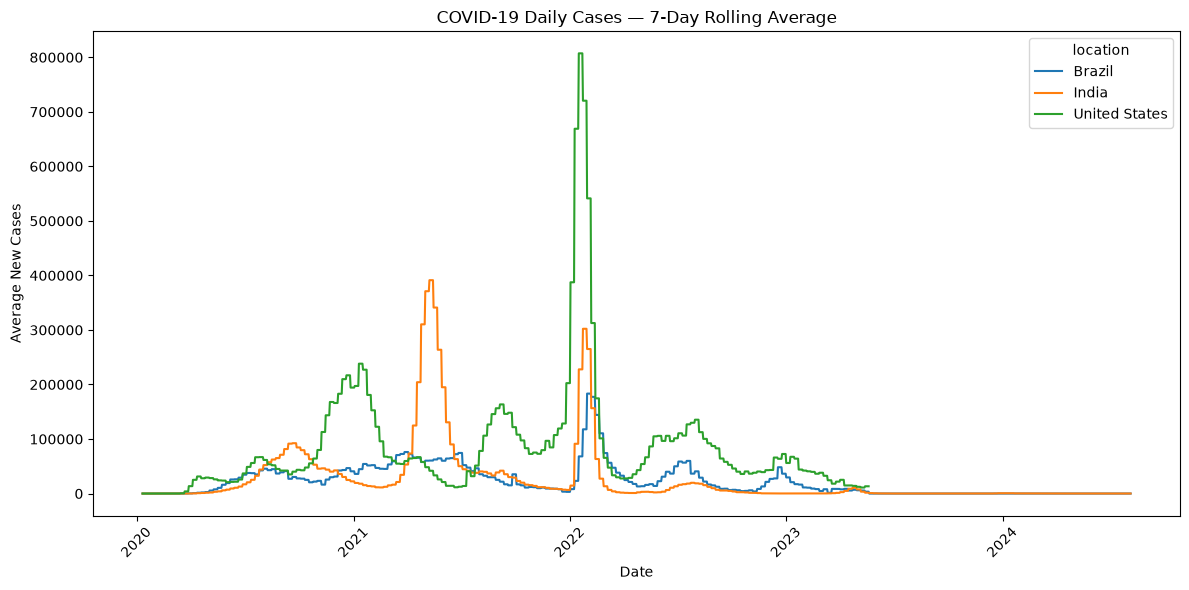

In [14]:
#Chart 1: COVID-19 Daily Cases — 7-Day Rolling Average
countries = ["India", "United States", "Brazil"]

trend_df = covid[
    covid["location"].isin(countries)
].copy()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=trend_df,
    x="date",
    y="new_cases_7day_avg",
    hue="location"
)

plt.title("COVID-19 Daily Cases — 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Average New Cases")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    CHART_DIR/"covid_cases_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

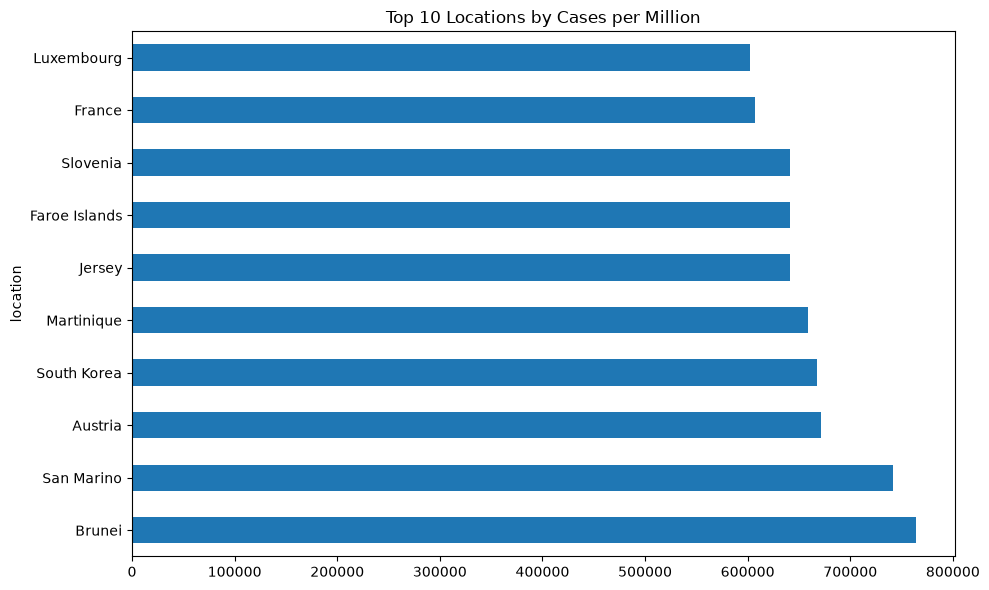

In [19]:
#Chart 2: Total cases per million
latest = (
    covid.dropna(subset=["total_cases_per_million"])
    .sort_values("date")
    .groupby("location")
    .tail(1)
)

latest = latest[
    ~latest["location"].isin([
        "World", "Asia", "Europe",
        "Africa", "North America",
        "South America", "Oceania"
    ])
]

top_cases = latest.nlargest(
    10, "total_cases_per_million"
)

top_cases.plot.barh(
    x="location",
    y="total_cases_per_million",
    figsize=(10, 6),
    legend=False
)

plt.title("Top 10 Locations by Cases per Million")
plt.tight_layout()
plt.savefig(
    CHART_DIR/"Top 10 Locations by Cases per Million",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

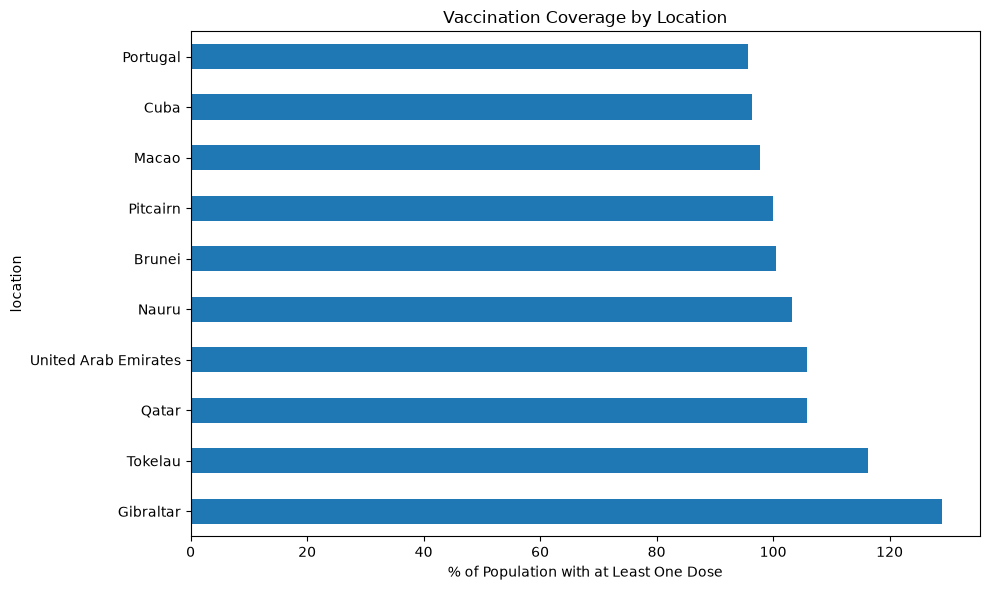

In [20]:
#Chart 3: Vaccination coverage
latest_vax = (
    covid.dropna(
        subset=["vaccination_coverage_pct"]
    )
    .sort_values("date")
    .groupby("location")
    .tail(1)
)

latest_vax = latest_vax[
    latest_vax["population"] > 0
].nlargest(10, "vaccination_coverage_pct")

latest_vax.plot.barh(
    x="location",
    y="vaccination_coverage_pct",
    figsize=(10, 6),
    legend=False
)

plt.title("Vaccination Coverage by Location")
plt.xlabel("% of Population with at Least One Dose")
plt.tight_layout()
plt.savefig(
    CHART_DIR/"Vaccination Coverage by Location",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

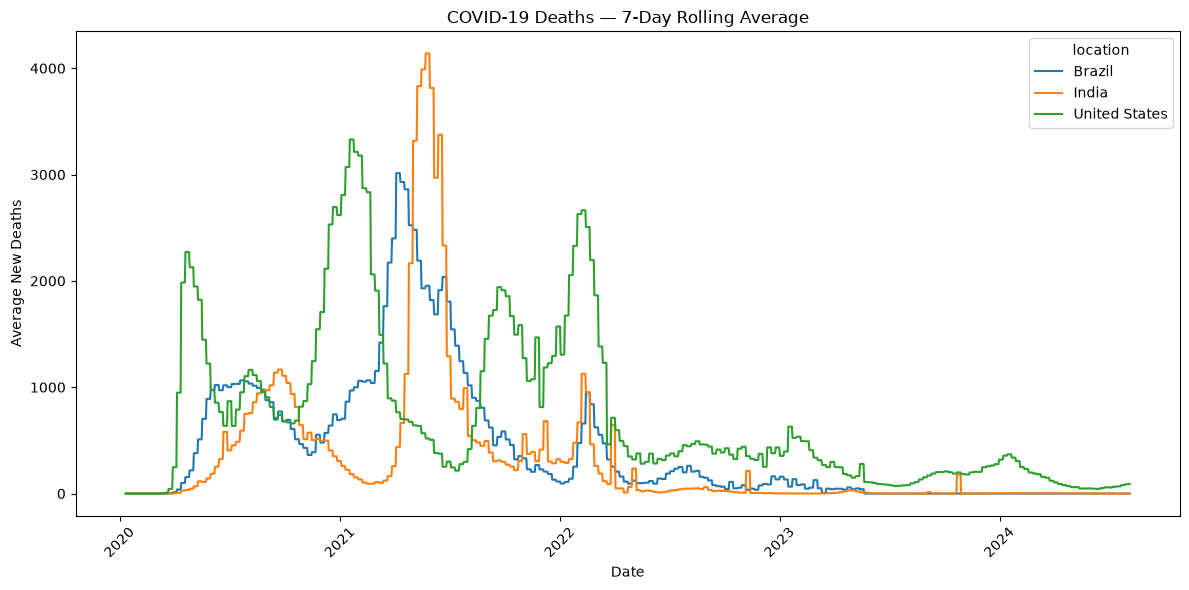

In [21]:
#Chart 4: Daily deaths trend
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=trend_df,
    x="date",
    y="new_deaths_7day_avg",
    hue="location"
)

plt.title("COVID-19 Deaths — 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Average New Deaths")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    CHART_DIR/"COVID-19 Deaths — 7-Day Rolling Average",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [22]:
CLEAN_DIR = BASE_DIR/ "Day2_Covid19_Global_Impact_Dashboard"/"Cleaned_Data"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

output_file = CLEAN_DIR / "covid19_cleaned_day2.csv"

covid.to_csv(output_file, index=False)

print("Saved cleaned dataset:", output_file)
print("Final rows and columns:", covid.shape)

Saved cleaned dataset: D:\Veda Internship\Sakshi\Super_Store_DataCleaning\COVID19_Global_Impact_Dashboard\Day2_Covid19_Global_Impact_Dashboard\Cleaned_Data\covid19_cleaned_day2.csv
Final rows and columns: (421665, 19)


In [23]:
print("Latest country-level data:")
print(
    latest[[
        "location", "total_cases_per_million",
        "total_deaths_per_million"
    ]].head(10)
)

print("\nVaccination coverage:")
print(
    latest_vax[[
        "location", "vaccination_coverage_pct"
    ]].head(10)
)

print("\nCases and deaths summary:")
print(
    covid[[
        "new_cases", "new_deaths",
        "new_cases_7day_avg", "new_deaths_7day_avg"
    ]].describe()
)

Latest country-level data:
                             location  total_cases_per_million  \
165530          High-income countries                 23955.62   
121936            European Union (27)                 25158.86   
408482  Upper-middle-income countries                  7646.93   
221499  Lower-middle-income countries                  5267.72   
347519                      Singapore                532073.56   
332822                          Samoa                 79235.75   
236997               Marshall Islands                406469.78   
334496                     San Marino                741418.25   
245371                         Mexico                 59243.24   
372629                    Switzerland                507026.47   

        total_deaths_per_million  
165530                    552.00  
121936                    612.33  
408482                    236.65  
221499                     95.74  
347519                    358.24  
332822                    144.01  
2

## Finding 1 — Countries with the Highest Reported Case Rates

The latest country-level summary shows high reported cumulative cases per million in San Marino (741,418.25), Mexico (59,243.24), and Switzerland (507,026.47). Singapore also recorded 532,073.56 cases per million. These values should be validated against the latest available records and interpreted as reported cases, not the true number of infections.

## Finding 2 — Vaccination Coverage Varied Across Countries

Reported vaccination coverage differed across locations. Gibraltar recorded 129.07%, Tokelau 116.38%, and Qatar 105.83% in the displayed data. Values above 100% are possible when reported vaccination counts and population estimates do not align, or when reporting and denominator definitions differ. They should be treated as data-quality flags rather than literal coverage of more than the population.

## Finding 3 — Daily Cases and Deaths Showed Highly Uneven Distributions

Across the dataset, the median daily new cases and new deaths were both zero, while the means were approximately 5,968 new cases and 57 new deaths per record. This indicates a highly skewed distribution, with many zero or low reported values and a smaller number of very large daily reports. These are averages across country-date records, not global daily totals.

## Finding 4 — Seven-Day Rolling Averages Smooth Daily Fluctuations

The seven-day rolling averages help reduce day-to-day reporting fluctuations and make case and death trends easier to compare over time. The exact dates and magnitudes of the peaks should be identified from the time-series analysis before reporting them.

## Finding 5 — Interpretation and Limitations

The dataset covers January 1, 2020, through August 14, 2024. Reporting differences, missing values, population estimates, and revisions to historical data can affect comparisons between countries. These descriptive results alone cannot establish that vaccination caused a reduction in deaths.

In [24]:
# find the exact peak dates
# Keep countries and territories, excluding OWID aggregate rows
if "iso_code" in df.columns:
    country_mask = (
        df["iso_code"].notna()
        & ~df["iso_code"].str.startswith("OWID_", na=False)
    )

    country_df = df.loc[
        country_mask,
        ["location", "date", "new_cases", "new_deaths",
         "new_cases_per_million", "total_cases_per_million",
         "people_vaccinated", "population"]
    ].copy()
else:
    # Fallback: remove common aggregate locations
    aggregate_names = [
        "World", "High-income countries",
        "Upper-middle-income countries",
        "Lower-middle-income countries",
        "Low-income countries", "European Union (27)",
        "Africa", "Asia", "Europe", "North America",
        "South America", "Oceania"
    ]

    country_df = covid[
        ~covid["location"].isin(aggregate_names)
    ].copy()

country_df["date"] = pd.to_datetime(country_df["date"])

country_df = country_df.sort_values(["location", "date"])

# Calculate seven-day averages
country_df["cases_7day_avg"] = (
    country_df.groupby("location")["new_cases"]
    .transform(lambda s: s.rolling(7, min_periods=7).mean())
)

country_df["deaths_7day_avg"] = (
    country_df.groupby("location")["new_deaths"]
    .transform(lambda s: s.rolling(7, min_periods=7).mean())
)

# Country with the largest reported seven-day average
case_peak = country_df.loc[
    country_df["cases_7day_avg"].idxmax()
]

death_peak = country_df.loc[
    country_df["deaths_7day_avg"].idxmax()
]

print("Largest reported case wave:")
print("Country:", case_peak["location"])
print("Peak date:", case_peak["date"].date())
print("7-day average:", round(case_peak["cases_7day_avg"], 2))

print("\nLargest reported death wave:")
print("Country:", death_peak["location"])
print("Peak date:", death_peak["date"].date())
print("7-day average:", round(death_peak["deaths_7day_avg"], 2))

Largest reported case wave:
Country: China
Peak date: 2022-12-25
7-day average: 5782211.0

Largest reported death wave:
Country: China
Peak date: 2023-02-05
7-day average: 6812.43


In [25]:
#2. Find the global peak period and compare cases with deaths
# Global daily totals using country-level records
daily_global = (
    country_df.groupby("date", as_index=False)
    .agg(
        global_new_cases=("new_cases", lambda s: s.sum(min_count=1)),
        global_new_deaths=("new_deaths", lambda s: s.sum(min_count=1))
    )
    .sort_values("date")
)

# Seven-day averages of the global totals
daily_global["cases_7day_avg"] = (
    daily_global["global_new_cases"]
    .rolling(7, min_periods=7).mean()
)

daily_global["deaths_7day_avg"] = (
    daily_global["global_new_deaths"]
    .rolling(7, min_periods=7).mean()
)

case_date = daily_global.loc[
    daily_global["cases_7day_avg"].idxmax()
]

death_date = daily_global.loc[
    daily_global["deaths_7day_avg"].idxmax()
]

print("Global case peak date:", case_date["date"].date())
print("Global cases 7-day average:",
      round(case_date["cases_7day_avg"]))

print("\nGlobal death peak date:", death_date["date"].date())
print("Global deaths 7-day average:",
      round(death_date["deaths_7day_avg"]))

print("\nPeak date difference:",
      abs((case_date["date"] - death_date["date"]).days),
      "days")

Global case peak date: 2022-12-25
Global cases 7-day average: 6319458

Global death peak date: 2021-01-24
Global deaths 7-day average: 14811

Peak date difference: 700 days


In [26]:
#3. Get a reliable country ranking for cases per million
latest_country = (
    country_df.dropna(subset=["total_cases_per_million"])
    .sort_values("date")
    .groupby("location")
    .tail(1)
)

top_10_cases = latest_country.nlargest(
    10, "total_cases_per_million"
)

print(top_10_cases[[
    "location",
    "date",
    "total_cases_per_million"
]].to_string(index=False))

     location       date  total_cases_per_million
       Brunei 2024-08-04                763598.60
   San Marino 2024-08-04                741418.25
      Austria 2024-08-04                671004.90
  South Korea 2024-08-04                667636.06
   Martinique 2024-08-04                659169.44
       Jersey 2024-08-04                641502.30
Faroe Islands 2024-08-04                641351.60
     Slovenia 2024-08-04                641340.20
       France 2024-08-04                606706.00
   Luxembourg 2024-08-04                602376.20


In [27]:
#4. Check vaccination coverage carefully
latest_vaccination = country_df.dropna(
    subset=["people_vaccinated", "population"]
).copy()

latest_vaccination = latest_vaccination[
    latest_vaccination["population"] > 0
].sort_values("date").groupby("location").tail(1)

latest_vaccination["vaccination_coverage_pct"] = (
    latest_vaccination["people_vaccinated"]
    / latest_vaccination["population"] * 100
)

print(
    latest_vaccination.nlargest(
        10, "vaccination_coverage_pct"
    )[[
        "location", "date", "vaccination_coverage_pct"
    ]].to_string(index=False)
)

            location       date  vaccination_coverage_pct
           Gibraltar 2022-12-16                129.066316
             Tokelau 2022-12-05                116.376123
               Qatar 2023-05-07                105.827064
United Arab Emirates 2022-06-20                105.825050
               Nauru 2023-02-20                103.270034
              Brunei 2023-06-30                100.478172
            Pitcairn 2022-08-29                100.000000
               Macao 2023-04-13                 97.773670
                Cuba 2024-04-12                 96.373343
            Portugal 2023-09-29                 95.624094
